# Reinforcement Learning for Two-Corrector Orbit Correction (NumPy DDPG)

Copyright (C) 2026 Hirokazu Maesaka, RIKEN SPring-8 Center. All rights reserved.

This program is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version.

This program is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with this program. If not, see <https://www.gnu.org/licenses/>.

## Overview

In an accelerator, the beam orbit deviates from the design orbit because of magnet misalignments, field errors,
and injection errors. Steering magnets (*correctors*) apply small angular kicks to bring the orbit back, using
beam position monitors (*BPMs*) as feedback. The standard method measures the **response matrix**, i.e. how the
BPM readings change per unit corrector kick, and inverts it.

In this notebook we pose the same task as a **reinforcement learning (RL)** problem: an *agent* repeatedly reads
the BPMs, changes the corrector kicks, and receives a *reward* when the orbit improves. The agent is never told
the optics or the incoming beam error; it must learn a correction strategy from interaction alone.

The toy problem is intentionally small (two correctors, one quadrupole, two BPMs) so that

- the classical solution is known exactly and serves as a reference, and
- every part of the RL algorithm can be written in plain NumPy and inspected line by line.

This notebook rewrites the original example to avoid `gymnasium`, `stable-baselines3`, and `torch`.
We keep the same two-corrector orbit-correction task, but implement a compact actor-critic learner in the style of
**DDPG** (Deep Deterministic Policy Gradient), with linear function approximators instead of deep networks:

- NumPy for simulation, replay buffer, policy, and learning updates
- SciPy linear algebra for stable critic fitting
- Matplotlib for diagnostics and plots

## Notebook outline

1. Linear-optics simulator of the toy beamline
2. Controllability check of the response matrix
3. RL environment: state, action, and reward
4. Classical response-matrix baseline
5. Actor-critic components: critic, actor, replay buffer, and warm start
6. Training loop
7. Evaluation: single seed, five seeds, and an example trajectory
8. Discussion, limitations, and exercises
9. Comparison with Bayesian optimization (Gaussian process)

## Learning goals

After working through this notebook you should be able to:

- Formulate orbit correction as a Markov decision process (state, action, reward, episode).
- Explain why the response-matrix method solves this toy problem in one step, and what an RL agent must learn instead.
- Describe the building blocks of an off-policy actor-critic method (DDPG): replay buffer, critic, target critic,
  deterministic actor, and exploration noise.
- Read a minimal NumPy implementation of these blocks and identify where it simplifies the full algorithm.
- Evaluate a learned controller with success rate and error statistics, and recognize the limits of such evaluations.
- Contrast a trained RL policy with per-episode Bayesian optimization in terms of the information and the number of
  machine measurements each method needs.

**Prerequisites:** linear transfer matrices in beam optics, basic linear algebra, and an introductory picture of RL
(agent, environment, reward).

## Setup

All random numbers derive from a single seed so that the notebook is reproducible.
The seed and most hyperparameters can be overridden by environment variables without editing the code.
For example, in Colab run `%env SEED=29` in a cell before executing the notebook from the top.

In [1]:
from __future__ import annotations

import os
import warnings
from dataclasses import dataclass
from typing import Final

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg
import scipy.stats
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel


def env_float(name: str, default: float) -> float:
    """Return float environment override or default."""
    raw_value = os.getenv(name)
    if raw_value is None:
        return default
    return float(raw_value)


def env_int(name: str, default: int) -> int:
    """Return int environment override or default."""
    raw_value = os.getenv(name)
    if raw_value is None:
        return default
    return int(raw_value)


DEFAULT_SEED: Final = 17
SEED: Final = env_int("SEED", DEFAULT_SEED)
RNG = np.random.default_rng(SEED)

print(f"NumPy: {np.__version__}")
print(f"SciPy: {__import__('scipy').__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Seed: {SEED}")

NumPy: 2.4.6
SciPy: 1.17.1
scikit-learn: 1.9.1
Seed: 17


## 1. Linear-optics simulator

We track a single particle in the horizontal plane with the state vector
$$
u = \begin{pmatrix}x \\ x' \end{pmatrix},
$$
where $x$ is the position [m] and $x'$ is the angle [rad]. Each element acts on $u$ as a linear map:

- Drift of length $L$:
$$
D(L)=\begin{pmatrix}1&L\\0&1\end{pmatrix}
$$
- Thin quadrupole of strength $k$:
$$
Q(k)=\begin{pmatrix}1&0\\-k&1\end{pmatrix}
$$
- Steering kick $\theta$:
$$
x' \leftarrow x' + \theta
$$


($k>0$ is focusing.) The beamline order is
`incoming beam -> C1 -> drift -> quad -> drift -> C2 -> drift -> BPM1 -> drift -> BPM2`:

| Element | Position $s$ [m] |
|---|---|
| Corrector C1 | 0.00 |
| Thin quadrupole | 0.60 |
| Corrector C2 | 1.00 |
| BPM1 | 1.70 |
| BPM2 | 2.20 |

**Hidden episode parameters.** At the start of every episode we draw, uniformly at random,

- the incoming offset $x_0 \in [-2, 2]$ mm and angle $x'_0 \in [-1.5, 1.5]$ mrad, and
- the quadrupole strength $k \in [-0.6, 0.6]$ m$^{-1}$.

They represent an unknown injection error and an unknown optics setting (e.g. a mis-set or drifting quadrupole).
The agent never sees them directly; it only sees BPM readings. Because $k$ changes from episode to episode,
no single fixed correction rule derived from one response matrix is exact for all episodes. This is what makes
the problem worth learning.

In [2]:
@dataclass(frozen=True)
class Lattice:
    """Geometry and hidden-latent limits for the two-corrector toy lattice."""

    drift_to_quad: float = 0.60
    drift_to_corrector_2: float = 0.40
    drift_to_bpm_1: float = 0.70
    drift_to_bpm_2: float = 0.50
    x0_limit: float = 2.0e-3
    xp0_limit: float = 1.5e-3
    k_limit: float = 0.60


LATTICE: Final = Lattice()


def drift(length: float) -> np.ndarray:
    """Return the 2x2 drift transfer matrix."""
    return np.array([[1.0, length], [0.0, 1.0]], dtype=np.float64)


def thin_quadrupole(strength: float) -> np.ndarray:
    """Return the 2x2 thin-quadrupole transfer matrix."""
    return np.array([[1.0, 0.0], [-strength, 1.0]], dtype=np.float64)


class BeamlineSimulator:
    """Propagate one horizontal trajectory for fixed hidden episode latents."""

    def __init__(self, lattice: Lattice) -> None:
        self.lattice = lattice
        self.x0 = 0.0
        self.xp0 = 0.0
        self.quadrupole_strength = 0.0

    def set_hidden_episode_state(self, x0: float, xp0: float, quadrupole_strength: float) -> None:
        """Set hidden episode parameters after range validation."""
        if abs(x0) > self.lattice.x0_limit or abs(xp0) > self.lattice.xp0_limit:
            raise ValueError("Incoming coordinates are outside configured limits.")
        if abs(quadrupole_strength) > self.lattice.k_limit:
            raise ValueError("Quadrupole strength is outside configured limits.")
        self.x0 = x0
        self.xp0 = xp0
        self.quadrupole_strength = quadrupole_strength

    def trajectory(self, kicks: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Return longitudinal positions and horizontal orbit along the beamline."""
        if kicks.shape != (2,):
            raise ValueError("Expected exactly two steering kicks.")
        state = np.array([self.x0, self.xp0 + kicks[0]], dtype=np.float64)
        positions = [0.0]
        orbit = [state[0]]

        state = drift(self.lattice.drift_to_quad) @ state
        positions.append(self.lattice.drift_to_quad)
        orbit.append(state[0])

        state = thin_quadrupole(self.quadrupole_strength) @ state
        state = drift(self.lattice.drift_to_corrector_2) @ state
        position_c2 = self.lattice.drift_to_quad + self.lattice.drift_to_corrector_2
        positions.append(position_c2)
        orbit.append(state[0])

        state[1] += kicks[1]
        state = drift(self.lattice.drift_to_bpm_1) @ state
        position_bpm1 = position_c2 + self.lattice.drift_to_bpm_1
        positions.append(position_bpm1)
        orbit.append(state[0])

        state = drift(self.lattice.drift_to_bpm_2) @ state
        positions.append(position_bpm1 + self.lattice.drift_to_bpm_2)
        orbit.append(state[0])
        return np.asarray(positions), np.asarray(orbit)

    def bpm_readings(self, kicks: np.ndarray) -> np.ndarray:
        """Return only BPM1 and BPM2 readings."""
        return self.trajectory(kicks)[1][-2:]

## 2. Controllability check

Because the model is linear, the BPM readings $y=(x_{\mathrm{BPM1}}, x_{\mathrm{BPM2}})^T$ are an affine function
of the kicks $\theta=(\theta_1,\theta_2)^T$:
$$
y(\theta) = y_0 + R(k)\,\theta,
$$
where $y_0$ is the orbit produced by the incoming error $(x_0, x'_0)$ alone and $R(k)$ is the $2\times2$ response matrix.
Writing the drift lengths as $L_1$ (C1 to quad), $L_2$ (quad to C2), $L_3$ (C2 to BPM1), and $L_4$ (BPM1 to BPM2),
the product of the transfer matrices gives
$$
R(k)=
\begin{pmatrix}
L_1 + (L_2+L_3)(1-kL_1) & L_3 \\
L_1 + (L_2+L_3+L_4)(1-kL_1) & L_3+L_4
\end{pmatrix}.
$$

If $R(k)$ is invertible, the kick $\theta^\ast = -R(k)^{-1}y_0$ zeros both BPMs exactly. We scan $k$ over its full
range and check two quantities:

- $\det R$ must stay away from zero, so that a unique solution exists.
- The smallest singular value $\sigma_{\min}$ indicates how much kick is needed in the weakest direction.
  A small $\sigma_{\min}$ means large kicks and high sensitivity to measurement noise.

Minimum |det(R)|: 0.428 m^2/rad^2
Minimum singular value: 0.153 m/rad


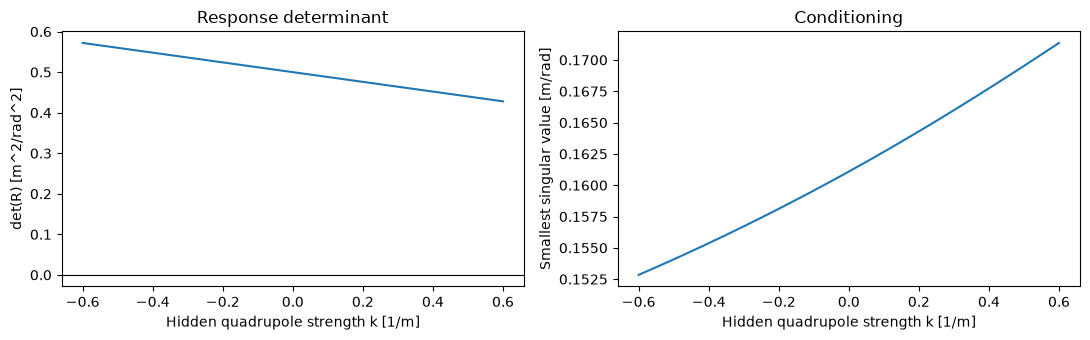

In [3]:
def analytic_response_matrix(quadrupole_strength: float, lattice: Lattice) -> np.ndarray:
    """Return the 2x2 analytic local response matrix."""
    q_transport = 1.0 - quadrupole_strength * lattice.drift_to_quad
    response_11 = lattice.drift_to_quad + (lattice.drift_to_corrector_2 + lattice.drift_to_bpm_1) * q_transport
    response_21 = response_11 + lattice.drift_to_bpm_2 * q_transport
    return np.array(
        [
            [response_11, lattice.drift_to_bpm_1],
            [response_21, lattice.drift_to_bpm_1 + lattice.drift_to_bpm_2],
        ],
        dtype=np.float64,
    )


k_scan = np.linspace(-LATTICE.k_limit, LATTICE.k_limit, 401)
determinants = np.asarray([np.linalg.det(analytic_response_matrix(k_value, LATTICE)) for k_value in k_scan])
smallest_singular_values = np.asarray(
    [np.linalg.svd(analytic_response_matrix(k_value, LATTICE), compute_uv=False)[-1] for k_value in k_scan]
)
assert np.min(np.abs(determinants)) > 0.40
assert np.min(smallest_singular_values) > 0.15
print(f"Minimum |det(R)|: {np.min(np.abs(determinants)):.3f} m^2/rad^2")
print(f"Minimum singular value: {np.min(smallest_singular_values):.3f} m/rad")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_scan, determinants)
axes[0].axhline(0.0, color="black", linewidth=0.8)
axes[0].set(xlabel="Hidden quadrupole strength k [1/m]", ylabel="det(R) [m^2/rad^2]", title="Response determinant")
axes[1].plot(k_scan, smallest_singular_values)
axes[1].set(xlabel="Hidden quadrupole strength k [1/m]", ylabel="Smallest singular value [m/rad]", title="Conditioning")
fig.tight_layout()

## 3. RL environment (without Gym)

RL formalizes control as a **Markov decision process (MDP)**. At each step $t$ the agent observes a state $s_t$,
chooses an action $a_t$, and the environment returns a reward $r_t$ and the next state $s_{t+1}$.
The agent aims to maximize the expected discounted return
$$
G = \sum_{t=0}^{T-1} \gamma^t r_t,\qquad 0<\gamma<1.
$$

We implement the environment as a plain class with `reset()` and `step(action)` methods that mirror the Gym API,
so no external package is needed.

- `reset()` draws new hidden parameters, sets both kicks to zero, and returns the first observation.
- `step(action)` updates the kicks, reads the BPMs, and returns `(observation, reward, done, info)`.
- An episode ends on success or after `MAX_STEPS = 35` steps.

### Observation

The observation is simply the pair of BPM readings in units of $s_{\mathrm{bpm}} = 1$ mm:
$$
s_t = \frac{y_t}{s_{\mathrm{bpm}}} = \left(\frac{x_{\mathrm{BPM1}}}{s_{\mathrm{bpm}}},\ \frac{x_{\mathrm{BPM2}}}{s_{\mathrm{bpm}}}\right).
$$
Scaling to order unity helps the regression-based learners below.

Note that $s_t$ does not reveal the hidden $k$, so the same reading may call for different kicks in different
episodes: the problem is *partially observable*. A controller can still succeed by applying a correction that is
good *on average* over $k$ and repeating it until the orbit converges. In principle the history also carries
information about $k$, because the change of the readings caused by an action satisfies
$\Delta y_t = \Delta\theta_{\max}R(k)\,a_{t-1}$. Exploiting this is left as an exercise (Section 8).

### Action

The action is a bounded incremental command $a_t\in[-1,1]^2$, mapped to kick increments:
$$
\theta_{t+1} = \mathrm{clip}\left(\theta_t + \Delta\theta_{\max}\,a_t,\ -\theta_{\max},\ \theta_{\max}\right),
\qquad \Delta\theta_{\max} = 0.8\ \mathrm{mrad},\quad \theta_{\max} = 4\ \mathrm{mrad}.
$$
Incremental actions mimic how operators adjust correctors in small steps and limit how far one bad action can
push the beam. As a consequence, a large initial error usually takes several steps to correct.

### Reward

The reward has two terms:
$$
r_t = c_{\mathrm{prog}}\left(\|s_t\|_2^2-\|s_{t+1}\|_2^2\right) + r_{\mathrm{success}},
$$

- The **progress term** ($c_{\mathrm{prog}}=0.2$) rewards every reduction of the squared orbit error. It gives dense
  feedback at every step; a reward given only on success would be *sparse* and much harder to learn from.
  Summed over an episode it telescopes to roughly $c_{\mathrm{prog}}(\|s_0\|^2-\|s_T\|^2)$ for $\gamma\approx1$,
  so it guides learning without changing which final state is best.
- The **success bonus** $r_{\mathrm{success}} = +5$ is added when $\max\lvert x_{\mathrm{BPM}}\rvert < 10$ µm,
  which also ends the episode. Otherwise the episode ends after `MAX_STEPS = 35` steps.

**Why the squared norm?** Since $s_{t+1} = s_t + (\Delta\theta_{\max}/s_{\mathrm{bpm}})R(k)\,a_t$, the squared
progress term is *quadratic* in the action and can be represented by the quadratic critic features of Section 5.
With the plain norm $\|s\|_2$, the reward has a cone-shaped kink at $s=0$ that a quadratic critic cannot fit.
In a test with the exploration noise used here, a critic fitted to the norm-based reward had an action gradient
$\nabla_a Q$ pointing *away* from the true improvement direction (cosine similarity $\approx -0.2$), and the
actor updates destroyed the warm-start policy within about 100 episodes. With the squared reward the cosine
similarity was $\approx +0.9$. The scale $c_{\mathrm{prog}}=0.2$ keeps per-step rewards of order ten even for
the largest initial errors ($\|s_0\|^2$ up to about $90$). The lesson is that a reward must suit the function
approximator, not only the task.

Earlier versions of this notebook also used an action cost, one-time bonuses at intermediate error thresholds,
and a time-out penalty. Removing them changed neither the training stability nor the final performance, so they
were dropped. Reward design strongly affects what an agent learns, but more terms are not automatically better.

In [4]:
BPM_SCALE: Final = 1.0e-3
MAX_KICK_INCREMENT: Final = 8.0e-4
MAX_KICK: Final = 4.0e-3
TARGET_TOLERANCE: Final = 1.0e-5
PROGRESS_REWARD_SCALE: Final = 0.2
SUCCESS_BONUS: Final = 5.0
MAX_STEPS: Final = 35


class TwoCorrectorOrbitEnv:
    """Minimal environment API with reset and step methods."""

    def __init__(self, lattice: Lattice, rng_seed: int) -> None:
        self.lattice = lattice
        self.rng = np.random.default_rng(rng_seed)
        self.simulator = BeamlineSimulator(lattice)
        self.kicks = np.zeros(2, dtype=np.float64)
        self.normalized_bpm = np.zeros(2, dtype=np.float64)
        self.step_count = 0

    def _squared_error(self) -> float:
        return float(np.dot(self.normalized_bpm, self.normalized_bpm))

    def reset(self) -> np.ndarray:
        x0 = self.rng.uniform(-self.lattice.x0_limit, self.lattice.x0_limit)
        xp0 = self.rng.uniform(-self.lattice.xp0_limit, self.lattice.xp0_limit)
        quadrupole_strength = self.rng.uniform(-self.lattice.k_limit, self.lattice.k_limit)
        self.simulator.set_hidden_episode_state(x0, xp0, quadrupole_strength)
        self.kicks = np.zeros(2, dtype=np.float64)
        self.normalized_bpm = self.simulator.bpm_readings(self.kicks) / BPM_SCALE
        self.step_count = 0
        return self.normalized_bpm.copy()

    def step(self, action: np.ndarray) -> tuple[np.ndarray, float, bool, dict]:
        clipped_action = np.clip(np.asarray(action, dtype=np.float64), -1.0, 1.0)
        previous_squared_error = self._squared_error()
        self.kicks = np.clip(self.kicks + MAX_KICK_INCREMENT * clipped_action, -MAX_KICK, MAX_KICK)
        self.step_count += 1
        readings = self.simulator.bpm_readings(self.kicks)
        self.normalized_bpm = readings / BPM_SCALE
        max_abs_reading = float(np.max(np.abs(readings)))
        is_success = max_abs_reading < TARGET_TOLERANCE
        reward = PROGRESS_REWARD_SCALE * (previous_squared_error - self._squared_error())
        if is_success:
            reward += SUCCESS_BONUS
        done = is_success or self.step_count >= MAX_STEPS
        info = {"is_success": is_success, "max_abs_reading": max_abs_reading}
        return self.normalized_bpm.copy(), reward, done, info


env_probe = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED)
observation = env_probe.reset()
print("Initial observation (normalized BPM readings):", observation)
assert observation.shape == (2,)

Initial observation (normalized BPM readings): [-0.40743349 -0.94265359]


## 4. Response-matrix baseline

The classical method first measures $R$ by probing each corrector around the current operating point:
$$
R_{:,j}\approx\frac{y(\theta+\delta e_j)-y(\theta-\delta e_j)}{2\delta},
$$
where $e_j$ is the unit vector for corrector $j$ and $\delta = 1$ µrad. It then applies one linear correction:
$$
\Delta\theta = -R^{-1}y.
$$

Because the model is linear and noiseless, a single correction reaches the target down to numerical round-off.
This is the reference: **in this idealized setting RL cannot beat the response-matrix method.** Note, however,
that the baseline needs four extra probe measurements per episode (since $k$ changes), whereas the RL agent uses
only its observations. The purpose of the exercise is the methodology. Learning a controller without a model
becomes attractive when the machine is nonlinear, noisy, or drifting, or when measuring $R$ is expensive.

In [5]:
RESPONSE_PROBE: Final = 1.0e-6


def estimate_response_matrix(simulator: BeamlineSimulator, kicks: np.ndarray, probe: float = RESPONSE_PROBE) -> np.ndarray:
    """Estimate the local 2x2 response matrix from symmetric kick probes."""
    response = np.empty((2, 2), dtype=np.float64)
    for column in range(2):
        positive = kicks.copy()
        negative = kicks.copy()
        positive[column] += probe
        negative[column] -= probe
        response[:, column] = (simulator.bpm_readings(positive) - simulator.bpm_readings(negative)) / (2.0 * probe)
    return response


def response_matrix_correction(environment: TwoCorrectorOrbitEnv) -> tuple[np.ndarray, np.ndarray]:
    """Apply one local response-matrix correction and return before/after BPM readings."""
    before = environment.simulator.bpm_readings(environment.kicks)
    response = estimate_response_matrix(environment.simulator, environment.kicks)
    kick_change = np.linalg.solve(response, -before)
    environment.kicks = np.clip(environment.kicks + kick_change, -MAX_KICK, MAX_KICK)
    after = environment.simulator.bpm_readings(environment.kicks)
    return before, after


baseline_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED + 1)
baseline_env.reset()
baseline_before, baseline_after = response_matrix_correction(baseline_env)
print("Baseline before [mm]:", 1.0e3 * baseline_before)
print("Baseline after [um]:", 1.0e6 * baseline_after)

Baseline before [mm]: [0.70273095 1.02734979]
Baseline after [um]: [2.10419346e-11 2.84958245e-11]


## 5. Actor-critic components in NumPy

### 5.1 Background: deterministic policy gradient (DDPG)

We use the actor-critic scheme of **DDPG** (Deep Deterministic Policy Gradient; Lillicrap et al., 2016), an
off-policy method for continuous actions. It has two learned functions:

- a **critic** $Q_w(s,a)$, which estimates the expected discounted return when taking action $a$ in state $s$ and
  following the policy afterwards, and
- an **actor** (policy) $\mu_W(s)$, which outputs a deterministic action.

The critic is trained toward the *Bellman target*
$$
y = r + \gamma\,(1-\mathrm{done})\,Q_{\bar w}\!\left(s', \mu_W(s')\right),
$$
where $Q_{\bar w}$ is a slowly moving *target critic*. The actor is improved by moving its action in the direction
in which the critic predicts a higher return (the deterministic policy gradient):
$$
\nabla_W J = \mathbb{E}_s\left[\nabla_a Q_w(s,a)\big|_{a=\mu_W(s)}\;\nabla_W\,\mu_W(s)\right].
$$
The ingredients are:

| Component | Role |
|---|---|
| Replay buffer | Stores past transitions $(s, a, r, s', \mathrm{done})$ so that data can be reused (off-policy learning). |
| Critic $Q_w$ | Estimates the return of action $a$ in state $s$; its action gradient tells the actor how to improve. |
| Target critic $Q_{\bar w}$ | Slowly moving copy (Polyak averaging) used in the Bellman target, which stabilizes learning. |
| Actor $\mu_W$ | Deterministic policy mapping the observation to an action in $[-1,1]^2$. |
| Exploration noise | Gaussian noise added to the actor output while collecting data. |

Modern variants such as TD3 and Soft Actor-Critic (SAC) add twin critics, target-policy smoothing, or a stochastic
policy with an entropy bonus. For this small problem those additions brought no measurable benefit, so we keep
the plain DDPG structure.

### 5.2 Function approximators

Deep RL uses neural networks for both functions. To stay NumPy-only we use simple linear models:

1. **Linear critic on quadratic features.** $Q_w(s,a) = w^T\varphi(s,a)$ with
   $$
   \varphi(s,a) = \left[1,\ s,\ a,\ s\otimes a,\ a^2,\ s^2\right]
   $$
   (13 features for the 2-dimensional $s$ and $a$). On each mini-batch with feature matrix $\Phi$ and Bellman
   targets $y$, the weights are moved toward the ridge-regression solution:
   $$
   w^\ast = (\Phi^T\Phi + \lambda I)^{-1}\Phi^T y,\qquad w \leftarrow (1-\beta)\,w + \beta\,w^\ast,
   $$
   with $\lambda$ = `CRITIC_RIDGE` and $\beta$ = `CRITIC_MIX`. Because $Q_w$ is quadratic in $a$, its action
   gradient $\nabla_a Q_w$ is available in closed form.
2. **Bias-free linear actor.**
   $$
   \mu_W(s) = \tanh(W s),
   $$
   with a $2\times2$ weight matrix $W$. The $\tanh$ keeps actions in $[-1,1]$. Its gradient follows from the chain
   rule, $\nabla_W \mu_i = (1-\mu_i^2)\,s^T$, so one actor step is
   $$
   W \leftarrow W + \eta\,\frac{1}{N}\sum_{n}\left[\nabla_a Q_w(s_n,a_n)\odot\left(1-a_n^2\right)\right]s_n^T,
   \qquad a_n=\mu_W(s_n),
   $$
   with learning rate $\eta$ = `ACTOR_LR`.

   **Why no bias?** Because the action is a kick *increment*, the closed loop acts as an integral controller: the
   kicks stop moving only where the action is zero. At the target orbit $s=0$, a bias-free actor gives exactly
   $\mu_W(0)=0$. A bias term would keep pushing the kicks at the target and leave a steady-state orbit offset of
   tens of micrometres. This is an example of building physical knowledge into the model structure
   (an *inductive bias*).

### 5.3 Warm start from the response-matrix oracle (behavior cloning)

Learning from scratch with such simple approximators is sample-inefficient. We therefore first collect
oracle pairs $(s_0, u^\ast)$ at the start of random episodes, with the unclipped normalized kick change
$$
u^\ast = -\frac{R^{-1}y_0}{\Delta\theta_{\max}},
$$
and fit the actor's pre-$\tanh$ output, $W s_0 \approx u^\ast$, by ridge regression without intercept.
Fitting to the unclipped $u^\ast$ lets $\tanh$ saturate large corrections naturally, whereas fitting
$\operatorname{arctanh}$ of clipped actions would turn the many saturated samples into huge, distorted targets.

This is *behavior cloning* (imitation learning); RL then fine-tunes the cloned policy. Since $R$ depends on the
hidden $k$, a single $W$ cannot reproduce the oracle exactly. Repeated application still converges, because the
closed-loop map $I + (\Delta\theta_{\max}/s_{\mathrm{bpm}})R(k)W$ is contracting over the whole $k$ range.

### 5.4 Evaluation helper

`evaluate_policy_success` runs the actor without exploration noise on fresh episodes and returns the mean return,
the success rate, the median final $\max\lvert x_{\mathrm{BPM}}\rvert$, and the mean number of steps per episode.

## 6. Training loop

Each episode has up to 35 steps and ends early on success. Learning is off-policy: every environment step adds one
transition to the replay buffer, and the learners are updated from random mini-batches of past transitions.
The procedure is:

1. Warm-start the actor from the oracle dataset (Section 5.3).
2. At every environment step:
   1. **Act.** Use uniformly random actions during the first `WARMUP_STEPS` steps to fill the buffer with diverse
      data; afterwards use the actor with exploration noise, $a = \tanh(Ws + \sigma\epsilon)$,
      $\epsilon\sim\mathcal{N}(0,I)$, $\sigma$ = `EXPLORATION_STD`.
   2. **Store** $(s, a, r, s', \mathrm{done})$ in the replay buffer.
   3. **Update** on a mini-batch of `BATCH_SIZE` transitions:
      - Compute Bellman targets $y = r + \gamma(1-\mathrm{done})\,Q_{\bar w}(s', \mu_W(s'))$.
      - Refit the critic (ridge regression with partial mixing).
      - Take one actor step along $\nabla_a Q_w$ (Section 5.2).
      - Polyak-average the target critic: $\bar w \leftarrow \tau\bar w + (1-\tau)w$ with $\tau$ = `POLYAK`.
3. Every `EVALUATION_INTERVAL_EPISODES` episodes, evaluate the actor without noise on fresh validation episodes and
   keep the best policy (highest success rate, ties broken by the mean number of steps per episode). Stop early
   after `EARLY_STOPPING_PATIENCE_EVALS` evaluations without improvement.
4. Restore the best policy.

**Why keep the best policy?** RL with function approximation is often non-monotonic: a policy can improve and then
degrade as the critic estimates shift. Checkpoint selection on validation episodes is common practice, but the final
performance then partly reflects this selection. Validation and final evaluation therefore use different random seeds.

**Simplifications relative to DDPG.** The Bellman target uses the current actor instead of a separate target
actor, and each step performs exactly one update. Both choices keep the loop short and made no difference here.

Fixed configuration (after multi-seed checks):

| Parameter | Value | Meaning |
|---|---|---|
| `GAMMA` | 0.98 | Discount factor $\gamma$ |
| `ACTOR_LR` | $2.0\times10^{-5}$ | Actor learning rate $\eta$ |
| `EXPLORATION_STD` | 0.2 | Standard deviation $\sigma$ of the exploration noise |
| `CRITIC_RIDGE` | $5.0\times10^{-3}$ | Ridge penalty $\lambda$ of the critic fit |
| `CRITIC_MIX` | 0.12 | Fraction $\beta$ of the new ridge solution mixed into the critic weights |
| `POLYAK` | 0.99 | Target-critic averaging factor $\tau$ |
| `BATCH_SIZE` | 256 | Transitions per update |
| `WARMUP_STEPS` | 1000 | Random-action steps before learning starts |
| `EVALUATION_INTERVAL_EPISODES` | 25 | Episodes between validation runs |
| `EARLY_STOPPING_PATIENCE_EVALS` | 10 | Validation runs without improvement before stopping |

`SEED`, `TRAIN_EPISODES`, `ORACLE_WARMSTART_SAMPLES`, `ACTOR_LR`, and `EXPLORATION_STD` can be overridden by
environment variables of the same name.

In [7]:
GAMMA: Final = 0.98
ACTOR_LR: Final = env_float("ACTOR_LR", 2.0e-5)
EXPLORATION_STD: Final = env_float("EXPLORATION_STD", 0.2)
CRITIC_RIDGE: Final = 5.0e-3
CRITIC_MIX: Final = 0.12
POLYAK: Final = 0.99
BATCH_SIZE: Final = 256
BUFFER_CAPACITY: Final = 60_000
WARMUP_STEPS: Final = 1_000
TRAIN_EPISODES: Final = env_int("TRAIN_EPISODES", 700)
ORACLE_WARMSTART_SAMPLES: Final = env_int("ORACLE_WARMSTART_SAMPLES", 8_000)
ORACLE_WARMSTART_RIDGE: Final = 1.0e-3
WARMSTART_EVAL_EPISODES: Final = 120
VALIDATION_EPISODES: Final = 80
EVALUATION_INTERVAL_EPISODES: Final = 25
EARLY_STOPPING_PATIENCE_EVALS: Final = 10

print(f"Training config: ACTOR_LR={ACTOR_LR:.2e}, EXPLORATION_STD={EXPLORATION_STD:.2f}, GAMMA={GAMMA:.2f}")

training_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED + 10)
evaluation_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED + 20)
state_dim = training_env.reset().shape[0]
action_dim = 2
critic = LinearCritic.create(feature_dim=critic_feature_dim(state_dim, action_dim), rng=RNG)
target_critic = LinearCritic(weights=critic.weights.copy())
replay = ReplayBuffer.create(capacity=BUFFER_CAPACITY, state_dim=state_dim, action_dim=action_dim)

warmstart_states, warmstart_kick_ratios = build_oracle_dataset(
    lattice=LATTICE,
    sample_count=ORACLE_WARMSTART_SAMPLES,
    rng_seed=SEED + 123,
)
policy = fit_policy_to_oracle(warmstart_states, warmstart_kick_ratios, ridge=ORACLE_WARMSTART_RIDGE)
warmstart_summary = evaluate_policy_success(policy, LATTICE, rng_seed=SEED + 220, episodes=WARMSTART_EVAL_EPISODES)
print(
    "Warm-start policy:",
    f"success={warmstart_summary.success_rate:.1f}%,",
    f"mean steps={warmstart_summary.mean_steps:.2f},",
    f"median error={warmstart_summary.median_error_um:.1f} um",
)

best_policy = policy.copy()
best_summary = warmstart_summary
evaluations_without_improvement = 0
completed_episodes = 0
episode_returns: list[float] = []
total_steps = 0
for episode in range(TRAIN_EPISODES):
    state = training_env.reset()
    cumulative_reward = 0.0
    done = False
    while not done:
        if total_steps < WARMUP_STEPS:
            action = RNG.uniform(-1.0, 1.0, size=action_dim)
        else:
            action = policy.noisy_action(state, EXPLORATION_STD, RNG)
        next_state, reward, done, _ = training_env.step(action)
        replay.add(state, action, reward, next_state, done)
        state = next_state
        cumulative_reward += reward
        total_steps += 1

        if replay.size < BATCH_SIZE or total_steps < WARMUP_STEPS:
            continue
        batch_states, batch_actions, batch_rewards, batch_next_states, batch_dones = replay.sample(BATCH_SIZE, RNG)
        next_q = target_critic.predict(batch_next_states, policy.actions(batch_next_states))
        bellman_targets = batch_rewards + GAMMA * (1.0 - batch_dones) * next_q
        critic.fit_batch(batch_states, batch_actions, bellman_targets, ridge=CRITIC_RIDGE, mix=CRITIC_MIX)
        actor_actions = policy.actions(batch_states)
        policy.update(batch_states, critic.action_gradient(batch_states, actor_actions), learning_rate=ACTOR_LR)
        target_critic.weights = POLYAK * target_critic.weights + (1.0 - POLYAK) * critic.weights

    completed_episodes += 1
    episode_returns.append(cumulative_reward)
    if (episode + 1) % EVALUATION_INTERVAL_EPISODES != 0:
        continue
    candidate_summary = evaluate_policy_success(policy, LATTICE, rng_seed=SEED + 330 + episode, episodes=VALIDATION_EPISODES)
    is_better = candidate_summary.success_rate > best_summary.success_rate or (
        np.isclose(candidate_summary.success_rate, best_summary.success_rate)
        and candidate_summary.mean_steps < best_summary.mean_steps
    )
    if is_better:
        best_summary = candidate_summary
        best_policy = policy.copy()
        evaluations_without_improvement = 0
    else:
        evaluations_without_improvement += 1
    print(
        f"Episode {episode + 1:4d}:",
        f"candidate success={candidate_summary.success_rate:.1f}%,",
        f"candidate steps={candidate_summary.mean_steps:.2f},",
        f"best success={best_summary.success_rate:.1f}%,",
        f"best steps={best_summary.mean_steps:.2f},",
        f"stale_evals={evaluations_without_improvement}",
    )
    if evaluations_without_improvement >= EARLY_STOPPING_PATIENCE_EVALS:
        print("Early stopping triggered by stagnant evaluation metrics.")
        break

print("Training episodes:", completed_episodes)
print("Replay size:", replay.size)
policy = best_policy
print("Restored best policy for final evaluation.")

Training config: ACTOR_LR=2.00e-05, EXPLORATION_STD=0.20, GAMMA=0.98
Warm-start policy: success=100.0%, mean steps=4.31, median error=3.7 um
Episode   25: candidate success=100.0%, candidate steps=4.46, best success=100.0%, best steps=4.31, stale_evals=1
Episode   50: candidate success=100.0%, candidate steps=4.06, best success=100.0%, best steps=4.06, stale_evals=0
Episode   75: candidate success=100.0%, candidate steps=3.99, best success=100.0%, best steps=3.99, stale_evals=0
Episode  100: candidate success=100.0%, candidate steps=4.05, best success=100.0%, best steps=3.99, stale_evals=1
Episode  125: candidate success=100.0%, candidate steps=3.89, best success=100.0%, best steps=3.89, stale_evals=0
Episode  150: candidate success=100.0%, candidate steps=3.91, best success=100.0%, best steps=3.89, stale_evals=1
Episode  175: candidate success=100.0%, candidate steps=3.99, best success=100.0%, best steps=3.89, stale_evals=2
Episode  200: candidate success=100.0%, candidate steps=4.10,

## 7. Evaluation

For evaluation we switch off the exploration noise and use the actor output $a=\tanh(Ws)$ directly.
The evaluation episodes come from a random seed not used during training or checkpoint selection. We report:

- **Mean return ± standard deviation:** the training objective, but hard to interpret physically.
- **Success rate:** the fraction of episodes reaching $\max\lvert x_{\mathrm{BPM}}\rvert < 10$ µm within 35 steps.
- **Mean steps per episode:** how fast the orbit is corrected. Failed episodes count as the full 35 steps. For comparison,
  repeating the exact response-matrix correction under the same action bound needs about 2.2 steps on average.
- **Median final error:** robust to a few diverging episodes. Because an episode ends as soon as the error falls
  below 10 µm, this value mostly reflects how far below the threshold the last step lands.

In [8]:
EVAL_EPISODES: Final = 150
evaluation_returns: list[float] = []
final_max_errors: list[float] = []
evaluation_lengths: list[int] = []
evaluation_successes: list[bool] = []
success_count = 0

for _ in range(EVAL_EPISODES):
    state = evaluation_env.reset()
    done = False
    episode_return = 0.0
    while not done:
        action = policy.action(state)
        state, reward, done, info = evaluation_env.step(action)
        episode_return += reward
    final_bpm = evaluation_env.simulator.bpm_readings(evaluation_env.kicks)
    final_max_error = float(np.max(np.abs(final_bpm)))
    final_max_errors.append(final_max_error)
    evaluation_returns.append(episode_return)
    evaluation_lengths.append(evaluation_env.step_count)
    evaluation_successes.append(bool(info["is_success"]))
    success_count += int(info["is_success"])

print(f"Evaluation mean return: {np.mean(evaluation_returns):.2f} +/- {np.std(evaluation_returns):.2f}")
print(f"Success rate: {100.0 * success_count / EVAL_EPISODES:.1f}%")
print(f"Mean steps per episode: {np.mean(evaluation_lengths):.2f}")
print(f"Median final max BPM error: {1.0e6 * np.median(final_max_errors):.1f} um")

Evaluation mean return: 6.74 +/- 2.58
Success rate: 100.0%
Mean steps per episode: 3.61
Median final max BPM error: 2.3 um


### 7.1 Five-seed evaluation sweep

To reduce single-seed bias, we evaluate the trained deterministic policy over
five independent environment seeds and report aggregate statistics.

Note that these seeds change only the *evaluation episodes*; the policy comes from one training run. The spread
therefore measures variability over test episodes, not the robustness of training. To assess the latter, rerun the
whole notebook with different `SEED` values and compare the results.

In [9]:
FIVE_SEED_LIST: Final[list[int]] = [17, 29, 41, 53, 67]
FIVE_SEED_EVAL_EPISODES: Final = 120
FIVE_SEED_OFFSET: Final = 50_000

five_seed_results: list[dict[str, float]] = []
for benchmark_seed in FIVE_SEED_LIST:
    benchmark_summary = evaluate_policy_success(
        policy=policy,
        lattice=LATTICE,
        rng_seed=FIVE_SEED_OFFSET + benchmark_seed,
        episodes=FIVE_SEED_EVAL_EPISODES,
    )
    five_seed_results.append(
        {
            "seed": float(benchmark_seed),
            "success_rate": benchmark_summary.success_rate,
            "mean_steps": benchmark_summary.mean_steps,
            "median_error_um": benchmark_summary.median_error_um,
        }
    )

print("Five-seed deterministic evaluation:")
for row in five_seed_results:
    print(
        f"  seed={int(row['seed']):2d}:",
        f"success={row['success_rate']:.1f}%,",
        f"mean steps={row['mean_steps']:.2f},",
        f"median error={row['median_error_um']:.1f} um",
    )

five_seed_success = np.asarray([row["success_rate"] for row in five_seed_results], dtype=np.float64)
five_seed_steps = np.asarray([row["mean_steps"] for row in five_seed_results], dtype=np.float64)
five_seed_median_error = np.asarray([row["median_error_um"] for row in five_seed_results], dtype=np.float64)
print(
    "Five-seed aggregate:",
    f"success mean={np.mean(five_seed_success):.1f}%,",
    f"success std={np.std(five_seed_success):.2f},",
    f"steps mean={np.mean(five_seed_steps):.2f},",
    f"steps std={np.std(five_seed_steps):.2f},",
    f"median error mean={np.mean(five_seed_median_error):.2f} um,",
    f"median error std={np.std(five_seed_median_error):.2f} um",
)

Five-seed deterministic evaluation:
  seed=17: success=100.0%, mean steps=3.79, median error=2.1 um
  seed=29: success=100.0%, mean steps=3.67, median error=2.1 um
  seed=41: success=100.0%, mean steps=3.73, median error=3.0 um
  seed=53: success=100.0%, mean steps=3.77, median error=1.9 um
  seed=67: success=100.0%, mean steps=3.52, median error=2.2 um
Five-seed aggregate: success mean=100.0%, success std=0.00, steps mean=3.70, steps std=0.10, median error mean=2.26 um, median error std=0.38 um


### 7.2 Training curve, error distribution, and steps to success

The left panel shows the return per training episode and its 20-episode moving average. RL learning curves are
noisy, and an upward trend does not guarantee that the latest policy is the best one (see Section 6).
The middle panel shows the distribution of the final $\max\lvert x_{\mathrm{BPM}}\rvert$ over the evaluation episodes
of Section 7, compared with the 10 µm success threshold.
The right panel shows how many steps the successful evaluation episodes needed. Failed episodes (if any) are
counted in the panel title instead of the histogram. Since every step can change each kick by at most
$\Delta\theta_{\max}$, episodes with a large initial error need more steps even with a perfect controller.

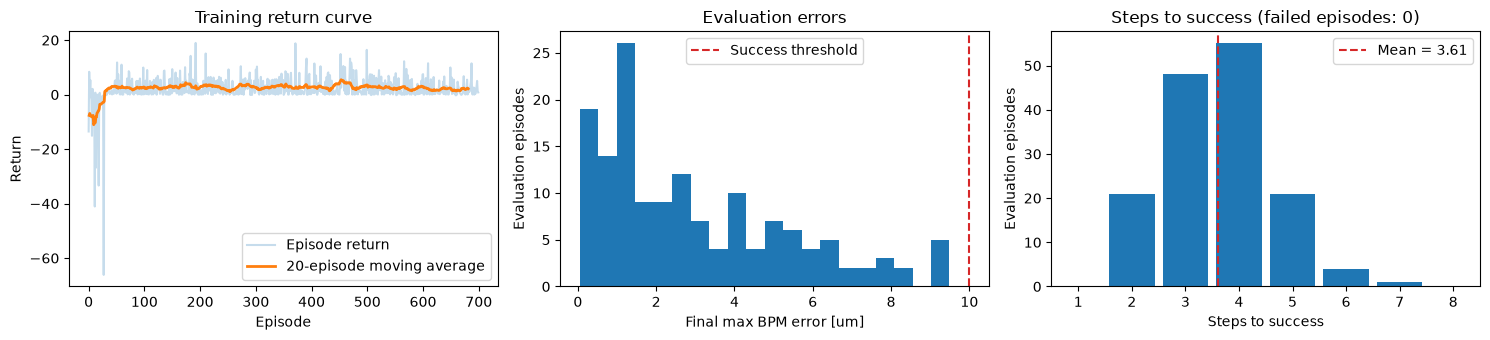

In [10]:
def moving_average(values: list[float], window: int = 20) -> np.ndarray:
    """Return trailing moving average."""
    if len(values) < 1:
        return np.asarray([], dtype=np.float64)
    window_size = min(window, len(values))
    kernel = np.ones(window_size, dtype=np.float64) / window_size
    return np.convolve(np.asarray(values, dtype=np.float64), kernel, mode="valid")


smoothed_returns = moving_average(episode_returns, window=20)
success_mask = np.asarray(evaluation_successes, dtype=bool)
steps_to_success = np.asarray(evaluation_lengths, dtype=np.int64)[success_mask]
failed_episode_count = int(np.count_nonzero(~success_mask))
step_bin_edges = np.arange(0.5, MAX_STEPS + 1.5, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(episode_returns, alpha=0.25, label="Episode return")
axes[0].plot(
    np.arange(len(smoothed_returns)) + 1,
    smoothed_returns,
    linewidth=2.0,
    label="20-episode moving average",
)
axes[0].set(xlabel="Episode", ylabel="Return", title="Training return curve")
axes[0].legend()
axes[1].hist(1.0e6 * np.asarray(final_max_errors), bins=20)
axes[1].axvline(1.0e6 * TARGET_TOLERANCE, color="tab:red", linestyle="--", label="Success threshold")
axes[1].set(xlabel="Final max BPM error [um]", ylabel="Evaluation episodes", title="Evaluation errors")
axes[1].legend()
axes[2].hist(steps_to_success, bins=step_bin_edges, rwidth=0.85)
if steps_to_success.size > 0:
    axes[2].axvline(
        np.mean(steps_to_success),
        color="tab:red",
        linestyle="--",
        label=f"Mean = {np.mean(steps_to_success):.2f}",
    )
    axes[2].set_xlim(0.5, steps_to_success.max() + 1.5)
    axes[2].legend()
axes[2].set(
    xlabel="Steps to success",
    ylabel="Evaluation episodes",
    title=f"Steps to success (failed episodes: {failed_episode_count})",
)
fig.tight_layout()

### 7.3 Before/after trajectory on one held-out episode

The policy observes only the two BPM readings at each step.
The full trajectory is shown only for visualization; the agent never sees the orbit between the BPMs.

Physics check: zeroing both BPMs means $x = x' = 0$ on the drift between them. Since there is no element after C2
other than drifts, the orbit is zero all the way from C2 to BPM2. Upstream of C2 the orbit stays nonzero, because
two BPMs can only constrain the beam downstream of the last corrector. Whether this particular episode reaches the
10 µm target depends on the trained policy; compare the printed final readings with the threshold.

Final BPM readings after RL correction [um]: [-1.54182282 -2.29637933]


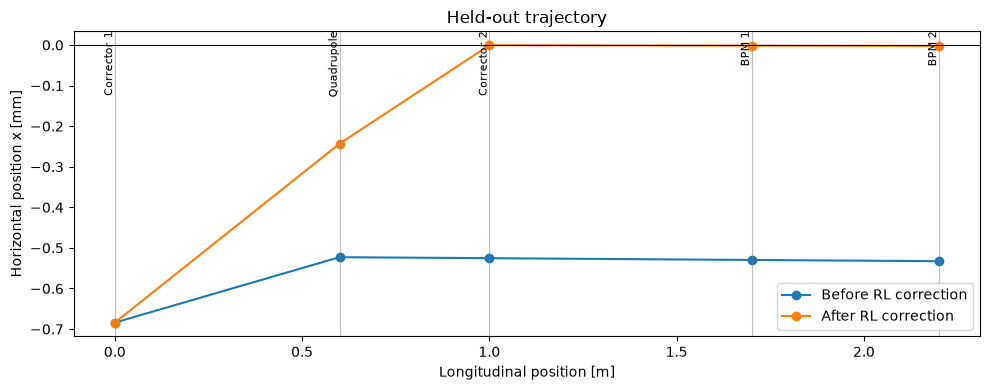

In [11]:
trajectory_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=20_026)
state = trajectory_env.reset()
positions, orbit_before = trajectory_env.simulator.trajectory(trajectory_env.kicks)
done = False
while not done:
    action = policy.action(state)
    state, _, done, _ = trajectory_env.step(action)
_, orbit_after = trajectory_env.simulator.trajectory(trajectory_env.kicks)

element_positions = positions
element_names = ["Corrector 1", "Quadrupole", "Corrector 2", "BPM 1", "BPM 2"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(positions, 1.0e3 * orbit_before, marker="o", label="Before RL correction")
ax.plot(positions, 1.0e3 * orbit_after, marker="o", label="After RL correction")
for element_position, element_name in zip(element_positions, element_names):
    ax.axvline(element_position, color="gray", linewidth=0.8, alpha=0.5)
    ax.text(element_position, ax.get_ylim()[1], element_name, rotation=90, va="top", ha="right", fontsize=8)
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set(xlabel="Longitudinal position [m]", ylabel="Horizontal position x [mm]", title="Held-out trajectory")
ax.legend()
fig.tight_layout()
print("Final BPM readings after RL correction [um]:", 1.0e6 * orbit_after[-2:])

## 8. Discussion and limitations

**RL versus the response-matrix method.** In this linear, noiseless model, the response-matrix correction is exact
after a few probe measurements, while the RL agent needs thousands of interaction steps and converges over several
steps. RL becomes attractive when the system is nonlinear, noisy, or drifting, when constraints matter, or when
measuring the response is costly. Even then, data efficiency and machine safety are major concerns: agents are
usually trained in simulation and then transferred to the real machine (*sim-to-real*), often combined with
model-based methods.

**What the RL fine-tuning achieves here.** The fine-tuning is stable (100% success throughout training) and reduces
the mean number of steps per episode from about 4.3 for the warm-start policy to about 3.7 (checked for
`SEED` = 17, 29, and 41). The warm start fits $W$ to one-step oracle corrections at episode starts, whereas RL
optimizes $W$ for the whole multi-step episode under the step limit $\Delta\theta_{\max}$ and the 10 µm target.
The remaining gap to the about 2.2 steps of repeating the exact correction would require a policy that adapts to
the hidden $k$, which in turn requires history in the observation (Exercise 3).

**What was simplified, and why.** An earlier, SAC-style version of this notebook was reduced step by step, and each
reduction was checked over several training seeds. None of the following degraded the training stability or the
final performance: removing the action cost, the milestone bonuses, and the time-out penalty from the reward;
shrinking the observation to the BPM readings; replacing twin critics by a single critic; removing the stochastic
policy and entropy bonus of SAC; and replacing a small neural-network actor by a linear one. Two choices, on the
other hand, were essential: the squared-error reward (Section 3) and the bias-free actor (Section 5.2).

**Implementation limitations.**

- This is a compact educational implementation of DDPG-style learning, not a full deep-RL stack.
- The critic is linear in hand-crafted features; this keeps dependencies minimal but limits how well $Q$ can be
  represented.
- Reaching the time limit sets `done = True` in the same way as success, so the critic treats a time-out as a true
  terminal state. Proper implementations distinguish *termination* from *truncation*
  (Gymnasium's `terminated` / `truncated` flags) and keep bootstrapping on truncation.
- Results come from a single training run with checkpoint selection; training variability is not quantified.

**Model limitations.**

- The machine model is linear, noiseless, and horizontal-only.
- For more realism, add noise, calibration drift, constraints, and temporal history.

## Exercises

1. **Effect of the warm start.** Set `%env ORACLE_WARMSTART_SAMPLES=0` and rerun. How do learning speed and final
   success rate change?
2. **Training variability.** Rerun the notebook with several `SEED` values and report the mean and spread of the
   final success rate. Compare with the spread of the five-seed evaluation in Section 7.1.
3. **Using history.** Add the BPM change $\Delta s_t$ and the previous action to the observation, and extend the
   critic features accordingly. Can the agent learn to adapt to the hidden $k$ and need fewer steps?
4. **Reward design.** Replace the squared-error progress term by the plain norm $\|s\|_2$. What happens to the
   critic's action gradient and to the policy during training?
5. **Measurement noise.** Add Gaussian BPM noise of a few micrometres in `bpm_readings`. How do the RL agent and the
   response-matrix baseline degrade? (Hint: the 1 µrad probe of the baseline becomes too small.)
6. **Exploration.** Vary `EXPLORATION_STD` (e.g. `%env EXPLORATION_STD=0.5`). How does the amount of exploration
   affect the critic and the stability of training?
7. **Toward TD3 or SAC.** Add a second critic and use the minimum of both in the Bellman target (TD3), or make the
   policy stochastic with an entropy bonus (SAC). Does either help in this problem?

## 9. Comparison with Bayesian optimization (Gaussian process)

A widely used alternative to RL for online accelerator tuning is **Bayesian optimization (BO)**. Instead of
learning a policy in advance, BO tunes each new situation from scratch: it treats the machine as a black-box function
of the knobs and chooses each new setting by balancing what it has already learned against what it has not
explored yet.

### 9.1 Problem setting

For every episode (fixed but unknown $x_0$, $x'_0$, $k$) we minimize the scalar orbit objective
$$
f(\theta) = \left\|\frac{y(\theta)}{s_{\mathrm{bpm}}}\right\|_2^2
$$
over the kicks $\theta\in[-\theta_{\max},\theta_{\max}]^2$. Each evaluation of $f$ means setting the correctors and
reading the BPMs once, i.e. one **machine measurement**, which corresponds to one RL step. BO starts from the reading
at $\theta=0$, which all methods get for free at reset, and stops as soon as an evaluated setting satisfies
$\max\lvert x_{\mathrm{BPM}}\rvert<10$ µm, or after `MAX_STEPS` evaluations.

### 9.2 Gaussian-process surrogate

Given evaluated points $X=\{\theta_i\}$ with values $F=\{f_i\}$, a Gaussian process with kernel $K$ gives the
posterior mean and variance at a new point $\theta$:
$$
\mu(\theta) = k_\theta^T\left(K + \sigma_n^2 I\right)^{-1}F,\qquad
\sigma^2(\theta) = K(\theta,\theta) - k_\theta^T\left(K + \sigma_n^2 I\right)^{-1}k_\theta,
$$
where $k_\theta = (K(\theta,\theta_i))_i$. We use scikit-learn's `GaussianProcessRegressor` with the kernel
$$
K(\theta,\theta') = c\,\exp\left(-\frac{\|\theta-\theta'\|^2}{2\ell^2}\right) + \sigma_n^2\,\delta_{\theta\theta'},
$$
i.e. `ConstantKernel * RBF + WhiteKernel`, on kicks normalized by $\theta_{\max}$. The hyperparameters $c$, $\ell$, and
$\sigma_n$ are refitted by maximum marginal likelihood after every new measurement.

### 9.3 Acquisition function: Expected Improvement

The next setting maximizes the **Expected Improvement** over the best value so far, $f^\ast=\min_i f_i$:
$$
\mathrm{EI}(\theta) = \left(f^\ast-\mu(\theta)\right)\Phi(z) + \sigma(\theta)\,\phi(z),\qquad
z = \frac{f^\ast-\mu(\theta)}{\sigma(\theta)},
$$
where $\Phi$ and $\phi$ are the standard normal CDF and PDF. The first term favors points predicted to be good
(*exploitation*), and the second favors uncertain points (*exploration*). We maximize EI over random candidates
spread over the whole box, plus candidates concentrated around the current best point. The latter are needed to
reach the micrometre-level target.

### 9.4 What each method uses

| Method | Information per measurement | Prior training | Step limit $\Delta\theta_{\max}$ |
|---|---|---|---|
| Response matrix (Section 4) | Both BPM readings (vector) | None, but assumes a linear model | Not applied |
| RL policy (Sections 5–7) | Both BPM readings (vector) | Thousands of simulated steps | Applied |
| Bayesian optimization | Scalar $f(\theta)$ only | None | Not applied (BO may jump anywhere in the box) |

The comparison is therefore not a contest on equal terms. It shows how prior knowledge (a model, or a policy
trained in simulation) and the richness of each measurement trade off against the number of measurements needed
on the machine.

In [12]:
BO_EPISODES: Final = env_int("BO_EPISODES", 60)
BO_RANDOM_CANDIDATES: Final = 2_000
BO_LOCAL_CANDIDATES: Final = 2_000
BO_LOCAL_SCALE: Final = 0.02
BO_GP_RESTARTS: Final = 1
BO_EI_STD_FLOOR: Final = 1.0e-12
COMPARISON_SEED: Final = SEED + 70_000
RESPONSE_MATRIX_MEASUREMENTS: Final = 5  # four probe readings plus one reading after the correction


@dataclass(frozen=True)
class CorrectionTrace:
    """Max BPM error after each machine measurement of one episode, and whether the target was reached."""

    max_errors: np.ndarray
    is_success: bool

    @property
    def measurements(self) -> int:
        return int(self.max_errors.size)


def orbit_objective(simulator: BeamlineSimulator, kicks: np.ndarray) -> float:
    """Return the squared normalized BPM error for the given kicks."""
    normalized = simulator.bpm_readings(kicks) / BPM_SCALE
    return float(np.dot(normalized, normalized))


def expected_improvement(mean: np.ndarray, std: np.ndarray, best_value: float) -> np.ndarray:
    """Return Expected Improvement for minimization."""
    improvement = best_value - mean
    safe_std = np.maximum(std, BO_EI_STD_FLOOR)
    z_score = improvement / safe_std
    return improvement * scipy.stats.norm.cdf(z_score) + safe_std * scipy.stats.norm.pdf(z_score)


def bayesian_optimization_episode(simulator: BeamlineSimulator, rng: np.random.Generator) -> CorrectionTrace:
    """Minimize the orbit objective for one episode with GP-based Bayesian optimization."""
    kernel = ConstantKernel(1.0, (1.0e-3, 1.0e3)) * RBF(0.5, (1.0e-2, 10.0)) + WhiteKernel(1.0e-6, (1.0e-10, 1.0e-2))
    normalized_points = [np.zeros(2, dtype=np.float64)]
    values = [orbit_objective(simulator, np.zeros(2, dtype=np.float64))]
    max_errors: list[float] = []
    for _ in range(MAX_STEPS):
        gaussian_process = GaussianProcessRegressor(
            kernel=kernel,
            normalize_y=True,
            n_restarts_optimizer=BO_GP_RESTARTS,
            random_state=int(rng.integers(2**31 - 1)),
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            gaussian_process.fit(np.asarray(normalized_points), np.asarray(values))
        best_point = normalized_points[int(np.argmin(values))]
        global_candidates = rng.uniform(-1.0, 1.0, size=(BO_RANDOM_CANDIDATES, 2))
        local_candidates = best_point + BO_LOCAL_SCALE * rng.standard_normal((BO_LOCAL_CANDIDATES, 2))
        candidates = np.clip(np.vstack([global_candidates, local_candidates]), -1.0, 1.0)
        mean, std = gaussian_process.predict(candidates, return_std=True)
        next_point = candidates[int(np.argmax(expected_improvement(mean, std, min(values))))]
        kicks = MAX_KICK * next_point
        normalized_points.append(next_point)
        values.append(orbit_objective(simulator, kicks))
        max_errors.append(float(np.max(np.abs(simulator.bpm_readings(kicks)))))
        if max_errors[-1] < TARGET_TOLERANCE:
            return CorrectionTrace(max_errors=np.asarray(max_errors), is_success=True)
    return CorrectionTrace(max_errors=np.asarray(max_errors), is_success=False)


def rl_policy_episode(environment: TwoCorrectorOrbitEnv, policy: LinearPolicy, state: np.ndarray) -> CorrectionTrace:
    """Run the deterministic RL policy from the given reset state and record the error after each step."""
    max_errors: list[float] = []
    done = False
    info = {"is_success": False}
    while not done:
        state, _, done, info = environment.step(policy.action(state))
        max_errors.append(info["max_abs_reading"])
    return CorrectionTrace(max_errors=np.asarray(max_errors), is_success=bool(info["is_success"]))


def response_matrix_episode(environment: TwoCorrectorOrbitEnv) -> CorrectionTrace:
    """Apply the one-shot response-matrix correction; probe readings are counted as measurements."""
    before, after = response_matrix_correction(environment)
    max_errors = np.full(RESPONSE_MATRIX_MEASUREMENTS, float(np.max(np.abs(before))))
    max_errors[-1] = float(np.max(np.abs(after)))
    return CorrectionTrace(max_errors=max_errors, is_success=bool(max_errors[-1] < TARGET_TOLERANCE))

### 9.5 Running the comparison

All three methods use environments created with the same seed, so they see identical sequences of hidden
parameters $(x_0, x'_0, k)$. The number of BO episodes can be changed with the environment variable `BO_EPISODES`;
each BO episode refits a GP up to 35 times and takes a fraction of a second.

In [13]:
comparison_rng = np.random.default_rng(COMPARISON_SEED)
comparison_environments = {
    "Response matrix": TwoCorrectorOrbitEnv(LATTICE, rng_seed=COMPARISON_SEED),
    "RL policy (DDPG)": TwoCorrectorOrbitEnv(LATTICE, rng_seed=COMPARISON_SEED),
    "Bayesian optimization": TwoCorrectorOrbitEnv(LATTICE, rng_seed=COMPARISON_SEED),
}
comparison_traces: dict[str, list[CorrectionTrace]] = {name: [] for name in comparison_environments}

for _ in range(BO_EPISODES):
    comparison_environments["Response matrix"].reset()
    comparison_traces["Response matrix"].append(response_matrix_episode(comparison_environments["Response matrix"]))

    rl_environment = comparison_environments["RL policy (DDPG)"]
    rl_state = rl_environment.reset()
    comparison_traces["RL policy (DDPG)"].append(rl_policy_episode(rl_environment, policy, rl_state))

    bo_environment = comparison_environments["Bayesian optimization"]
    bo_environment.reset()
    comparison_traces["Bayesian optimization"].append(
        bayesian_optimization_episode(bo_environment.simulator, comparison_rng)
    )

print(f"Comparison over {BO_EPISODES} identical episodes:")
for name, traces in comparison_traces.items():
    successes = np.asarray([trace.is_success for trace in traces])
    measurements = np.asarray([trace.measurements for trace in traces])
    final_errors_um = 1.0e6 * np.asarray([trace.max_errors[-1] for trace in traces])
    mean_successful = float(np.mean(measurements[successes])) if np.any(successes) else float("nan")
    print(
        f"  {name:22s}:",
        f"success={100.0 * np.mean(successes):5.1f}%,",
        f"mean measurements (successful)={mean_successful:5.2f},",
        f"median final error={np.median(final_errors_um):7.2f} um",
    )

Comparison over 60 identical episodes:
  Response matrix       : success=100.0%, mean measurements (successful)= 5.00, median final error=   0.00 um
  RL policy (DDPG)      : success=100.0%, mean measurements (successful)= 3.92, median final error=   2.81 um
  Bayesian optimization : success= 85.0%, mean measurements (successful)=15.98, median final error=   7.89 um


### 9.6 Convergence and measurement count

The left panel shows the median over episodes of the best $\max\lvert x_{\mathrm{BPM}}\rvert$ reached so far
versus the number of machine measurements (the bands span the 25th to 75th percentiles). The RL policy and BO
continue only until success, so a finished episode keeps its final value. The response-matrix method
reaches the target after its fifth measurement; its residual (about $10^{-10}$ µm, numerical round-off) lies below
the plotted range and is drawn at the lower edge of the panel. The right panel shows the distribution of the number
of measurements needed for success.

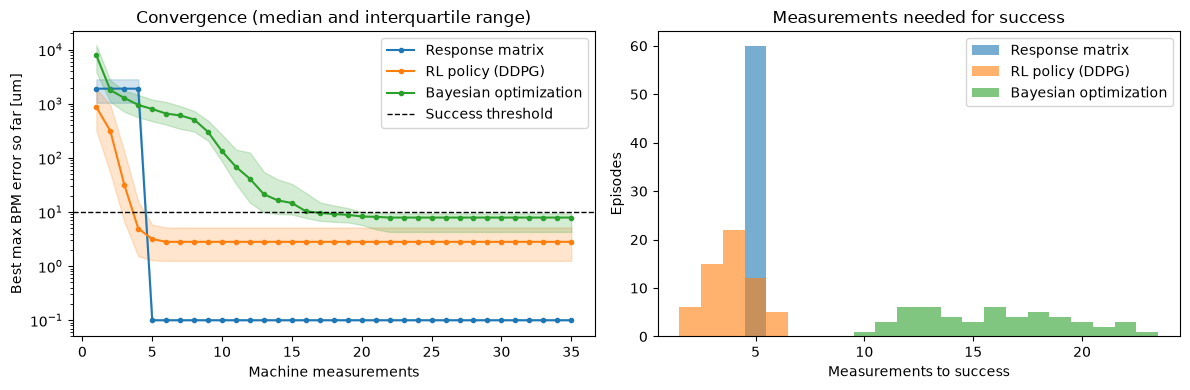

In [14]:
def best_so_far_matrix(traces: list[CorrectionTrace], length: int) -> np.ndarray:
    """Return best-so-far max BPM error per measurement, padded with the final value after termination."""
    matrix = np.empty((len(traces), length), dtype=np.float64)
    for row, trace in enumerate(traces):
        running_best = np.minimum.accumulate(trace.max_errors)
        matrix[row, : running_best.size] = running_best[:length]
        matrix[row, running_best.size :] = running_best[-1]
    return matrix


QUARTILES: Final = (25.0, 50.0, 75.0)
CONVERGENCE_PLOT_FLOOR_UM: Final = 0.1
measurement_axis = np.arange(1, MAX_STEPS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, traces in comparison_traces.items():
    best_so_far_um = np.maximum(1.0e6 * best_so_far_matrix(traces, MAX_STEPS), CONVERGENCE_PLOT_FLOOR_UM)
    lower, median, upper = np.percentile(best_so_far_um, QUARTILES, axis=0)
    line = axes[0].plot(measurement_axis, median, marker=".", label=name)[0]
    axes[0].fill_between(measurement_axis, lower, upper, color=line.get_color(), alpha=0.2)
axes[0].axhline(1.0e6 * TARGET_TOLERANCE, color="black", linestyle="--", linewidth=1.0, label="Success threshold")
axes[0].set_yscale("log")
axes[0].set_ylim(bottom=0.5 * CONVERGENCE_PLOT_FLOOR_UM)
axes[0].set(
    xlabel="Machine measurements",
    ylabel="Best max BPM error so far [um]",
    title="Convergence (median and interquartile range)",
)
axes[0].legend()

measurement_bins = np.arange(0.5, MAX_STEPS + 1.5, 1.0)
largest_successful_count = 1
for name, traces in comparison_traces.items():
    successful_counts = [trace.measurements for trace in traces if trace.is_success]
    axes[1].hist(successful_counts, bins=measurement_bins, alpha=0.6, label=name)
    largest_successful_count = max([largest_successful_count, *successful_counts])
axes[1].set_xlim(0.5, largest_successful_count + 1.5)
axes[1].set(
    xlabel="Measurements to success",
    ylabel="Episodes",
    title="Measurements needed for success",
)
axes[1].legend()
fig.tight_layout()

### 9.7 Discussion

- **Response matrix:** with a linear, noiseless model and vector BPM readings, a few probe measurements determine
  the correction exactly, down to numerical round-off. This is the most accurate method whenever its model
  assumptions hold.
- **RL policy:** after training, the policy corrects a new episode without probing, typically in slightly fewer
  measurements than the response-matrix method, but only to the 10 µm target. Its correction strategy is
  *amortized*: the cost was paid in advance by thousands of simulated training steps. It is also the only method
  here limited to small kick increments, which mainly sets its number of steps.
- **Bayesian optimization:** BO needs no model and no training, and it sees only a scalar objective. It must
  discover the two-dimensional structure of $f(\theta)$ from scratch in every episode, so it needs many more
  measurements than the other methods, and some episodes may not reach the micrometre-level target within
  the budget. In return, it extends naturally to nonlinear objectives, noisy measurements, and
  knobs for which no model or simulator exists.

In practice these methods are complementary. For example, a policy or model provides a good starting point, and
BO fine-tunes it on the real machine. Here the BO objective is an analytic quadratic bowl; on a real machine the GP
noise term $\sigma_n$ becomes essential.

**Exercises for this section.**

1. Replace Expected Improvement by the upper (lower) confidence bound $\mu(\theta)-\kappa\sigma(\theta)$ and vary $\kappa$.
2. Add BPM noise and observe how the fitted `WhiteKernel` level and the BO convergence change.
3. Give BO the same step limit as RL by restricting candidates to $\lvert\theta-\theta_{\mathrm{last}}\rvert\le\Delta\theta_{\max}$.
4. Start BO from the kicks proposed by one RL step instead of $\theta=0$ (warm-started BO).